# Analyse de sentiment des avis — approche NLP

Objectif : reproduire la classification faite par le LLM (`Sentiment` = `1` / `0` / `-1`)
avec des méthodes **NLP classiques**, sans API et sans coût.

Deux approches complémentaires :

1. **VADER** — lexique de sentiment (règles, négations, intensificateurs).
   Non supervisé, très rapide, aucune donnée d'entraînement nécessaire.
2. **TF-IDF + Régression logistique** — modèle supervisé entraîné sur les notes
   (`Rating`) utilisées comme vérité terrain.

| | Entrée | Sortie |
|---|---|---|
| Fichier | `data/processed/reviews_for_llm.csv` | `data/processed/reviews_nlp_sentiment.csv` |
| Colonnes | `ReviewId, Review, Rating` | `ReviewId, Review, Rating, Sentiment` |

Valeurs de `Sentiment` (identiques au pipeline LLM) :

- `1` : avis positif
- `0` : avis négatif
- `-1` : exception (texte illisible, erreur de traitement)


## 1. Configuration

In [1]:
import json
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix)
from sklearn.model_selection import train_test_split
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Remonte les dossiers jusqu'à trouver data/processed."""
    for parent in [start, *start.parents]:
        if (parent / "data" / "processed").is_dir():
            return parent
    return start


PROJECT_ROOT = find_project_root()

INPUT_PATH = PROJECT_ROOT / "data" / "processed" / "reviews_for_llm.csv"
OUTPUT_PATH = PROJECT_ROOT / "data" / "processed" / "reviews_nlp_sentiment.csv"
CHECKPOINT_PATH = PROJECT_ROOT / "data" / "processed" / "nlp_sentiment_checkpoint.json"

# Taille des blocs lus/écrits (permet de traiter 1,4 M d'avis sans saturer la RAM).
CHUNK_SIZE = 50_000

# Pour tester rapidement sur un échantillon : os.environ["NB_ROW_LIMIT"] = "20000"
ROW_LIMIT = int(os.environ["NB_ROW_LIMIT"]) if os.environ.get("NB_ROW_LIMIT") else None

# Taille de l'échantillon d'entraînement du modèle supervisé.
ML_SAMPLE = 200_000

RANDOM_STATE = 42

print("Projet :", PROJECT_ROOT)
print("Entrée :", INPUT_PATH, "| existe :", INPUT_PATH.exists())
print("Sortie :", OUTPUT_PATH)
print("Limite :", ROW_LIMIT or "aucune")

Projet : D:\TEK-UP University\ING-5-J-SDIA-F-A\Projet_BIGDATA_DeepLearning\adaptive-recipe-copilot
Entrée : D:\TEK-UP University\ING-5-J-SDIA-F-A\Projet_BIGDATA_DeepLearning\adaptive-recipe-copilot\data\processed\reviews_for_llm.csv | existe : True
Sortie : D:\TEK-UP University\ING-5-J-SDIA-F-A\Projet_BIGDATA_DeepLearning\adaptive-recipe-copilot\data\processed\reviews_nlp_sentiment.csv
Limite : aucune


## 2. Chargement des avis

Le fichier `reviews_for_llm.csv` est déjà nettoyé (3 colonnes, une ligne par avis).
On vérifie sa structure et on affiche un aperçu.

In [2]:
df = pd.read_csv(INPUT_PATH, dtype={"ReviewId": "Int64", "Review": "string",
                                     "Rating": "Int64"}, nrows=5)
df

,ReviewId,Rating,Review
0,2,5,better than any you can get at a restaurant!
1,7,4,"I cut back on the mayo, and made up the differ..."
2,9,2,i think i did something wrong because i could ...
3,13,5,easily the best i have ever had. juicy flavorf...
4,14,5,An excellent dish.


In [3]:
nb_lignes = sum(1 for _ in open(INPUT_PATH, encoding="utf-8", errors="ignore")) - 1
print(f"{nb_lignes:,} avis dans le fichier".replace(",", " "))

1 401 982 avis dans le fichier


## 3. Approche 1 — VADER (lexique)

VADER renvoie un score `compound` entre -1 et +1 :

- `compound >= 0.05` → avis positif (`1`)
- `compound <= -0.05` → avis négatif (`0`)
- sinon (neutre) → on tranche avec la note : `Rating >= 4` → `1`,
  `Rating <= 2` → `0`, `Rating == 3` → `1`
- texte vide ou trop court → on utilise uniquement la note


In [4]:
analyzer = SentimentIntensityAnalyzer()


def label_from_rating(rating) -> int:
    """Sentiment déduit de la note seule (repli)."""
    if pd.isna(rating):
        return -1
    rating = int(rating)
    if rating >= 4:
        return 1
    if rating <= 2:
        return 0
    return 1  # note moyenne : on considère l'avis comme positif par défaut


def vader_sentiment(text, rating, cache=None) -> int:
    """Retourne 1 (positif), 0 (négatif) ou -1 (exception)."""
    try:
        texte = "" if text is None else str(text).strip()
        if len(texte) < 3:
            return label_from_rating(rating)

        if cache is not None and texte in cache:
            score = cache[texte]
        else:
            score = analyzer.polarity_scores(texte)["compound"]
            if cache is not None and len(cache) < 500_000:
                cache[texte] = score

        if score >= 0.05:
            return 1
        if score <= -0.05:
            return 0
        return label_from_rating(rating)
    except Exception:
        return -1


exemples = [
    ("better than any you can get at a restaurant!", 5),
    ("i think i did something wrong because i could taste the cornstarch", 2),
    ("The recipe was okay, nothing special.", 3),
    ("", 4),
]
for texte, note in exemples:
    print(f"{vader_sentiment(texte, note):>2} | note {note} | "
          f"{analyzer.polarity_scores(texte)['compound']:+.2f} | {texte[:60]}")

 1 | note 5 | +0.49 | better than any you can get at a restaurant!
 0 | note 2 | -0.48 | i think i did something wrong because i could taste the corn
 0 | note 3 | -0.09 | The recipe was okay, nothing special.
 1 | note 4 | +0.00 | 


## 4. Classification complète (VADER)

Le traitement est **incrémental** : chaque bloc de `CHUNK_SIZE` avis est écrit
immédiatement dans le CSV, et un checkpoint enregistre la dernière ligne
terminée. Si le notebook est interrompu, il reprend automatiquement.

Un cache évite de recalculer le score des textes identiques (les avis répétés
sont fréquents), ce qui accélère beaucoup le traitement.


In [5]:
def process_vader(input_path=INPUT_PATH, output_path=OUTPUT_PATH,
                  checkpoint_path=CHECKPOINT_PATH, chunk_size=CHUNK_SIZE,
                  row_limit=ROW_LIMIT, verbose=True):
    """Classifie tous les avis avec VADER, avec reprise sur checkpoint."""
    start_line = 1
    if checkpoint_path.exists() and output_path.exists():
        checkpoint = json.loads(checkpoint_path.read_text(encoding="utf-8"))
        if checkpoint.get("input") == str(input_path):
            start_line = int(checkpoint.get("last_completed_line", 0)) + 1

    cache = {}
    done = 0
    errors = 0
    debut = time.time()
    offset = 0  # lignes déjà lues

    reader = pd.read_csv(
        input_path,
        chunksize=chunk_size,
        dtype={"ReviewId": "Int64", "Review": "string", "Rating": "Int64"},
        keep_default_na=False,
        na_values=[""],
    )

    for chunk in reader:
        chunk = chunk.reset_index(drop=True)
        taille_lue = len(chunk)
        begin = max(0, (start_line - 1) - offset)
        if begin >= taille_lue:
            offset += taille_lue
            continue
        if row_limit is not None:
            reste = row_limit - done
            if reste <= 0:
                break
            chunk = chunk.iloc[begin:begin + reste]
        else:
            chunk = chunk.iloc[begin:]
        offset += taille_lue

        labels = []
        for texte, note in zip(chunk["Review"], chunk["Rating"]):
            cle = "" if pd.isna(texte) else str(texte)
            labels.append(vader_sentiment(cle, note, cache))

        chunk = chunk.copy()
        chunk["Sentiment"] = labels

        header = not output_path.exists() or output_path.stat().st_size == 0
        chunk.to_csv(output_path, mode="a", header=header, index=False)

        done += len(chunk)
        errors += sum(1 for x in labels if x == -1)

        checkpoint_path.write_text(json.dumps({
            "input": str(input_path),
            "output": str(output_path),
            "last_completed_line": start_line - 1 + done,
            "rows_done": done,
            "errors": errors,
            "updated_at": pd.Timestamp.now().isoformat(timespec="seconds"),
        }, indent=2), encoding="utf-8")

        ecoule = time.time() - debut
        vitesse = done / ecoule if ecoule else 0
        if verbose:
            print(f"[{done:>9,}] ligne {start_line - 1 + done:>9,} | "
                  f"{vitesse:>8,.0f} avis/s | -1: {errors}".replace(",", " "),
                  flush=True)

    print(f"\nTerminé : {done:,} avis en {time.time() - debut:.1f} s".replace(",", " "))
    return done

In [6]:
# Pour repartir de zéro : supprimer le CSV et le checkpoint
for chemin in (OUTPUT_PATH, CHECKPOINT_PATH):
    chemin.unlink(missing_ok=True)

process_vader()

[   50 000] ligne    50 000 |    4 118 avis/s | -1: 0


[  100 000] ligne   100 000 |    4 027 avis/s | -1: 0


[  150 000] ligne   150 000 |    3 969 avis/s | -1: 0


[  200 000] ligne   200 000 |    3 980 avis/s | -1: 0


[  250 000] ligne   250 000 |    3 986 avis/s | -1: 0


[  300 000] ligne   300 000 |    3 986 avis/s | -1: 0


... (21 outputs left out)

[1 400 000] ligne 1 400 000 |    3 739 avis/s | -1: 0


[1 401 982] ligne 1 401 982 |    3 740 avis/s | -1: 0



Terminé : 1 401 982 avis en 374.9 s


1401982

## 5. Résultats et qualité de la classification VADER

In [7]:
resultat = pd.read_csv(OUTPUT_PATH)
print("Lignes :", f"{len(resultat):,}".replace(",", " "))
print("ReviewId uniques :", f"{resultat['ReviewId'].nunique():,}".replace(",", " "))
print()
print(resultat["Sentiment"].value_counts().sort_index())
print()
print("Croisement Note / Sentiment :")
pd.crosstab(resultat["Rating"], resultat["Sentiment"], margins=True)

Lignes : 1 401 982
ReviewId uniques : 1 401 982

Sentiment
0      57564
1    1344418
Name: count, dtype: int64

Croisement Note / Sentiment :


Sentiment,0,1,All
Rating,,,
0,15169,61079,76248
1,9707,6852,16559
2,6771,10826,17597
3,6544,43735,50279
4,6494,222723,229217
5,12879,999203,1012082
All,57564,1344418,1401982


In [8]:
# Part d'avis où VADER est d'accord avec la note (>=4 -> positif, <=2 -> négatif)
note_binaire = resultat["Rating"].map(lambda r: 1 if r >= 4 else (0 if r <= 2 else np.nan))
comparable = note_binaire.notna() & resultat["Sentiment"].isin([0, 1])
accord = (note_binaire[comparable] == resultat.loc[comparable, "Sentiment"]).mean()
print(f"Accord VADER / note ({comparable.sum():,} avis) : {accord:.1%}".replace(",", " "))

Accord VADER / note (1 351 703 avis) : 92.7%


## 6. Approche 2 — TF-IDF + Régression logistique

VADER ne connaît pas le vocabulaire culinaire. On entraîne donc un modèle
supervisé sur les notes :

- `Rating >= 4` → `1` (positif)
- `Rating <= 2` → `0` (négatif)
- `Rating == 3` → exclu (ambigu)

Les avis sont vectorisés en TF-IDF (uni- et bigrammes) puis classés par une
régression logistique.


In [9]:
def charger_echantillon(path=INPUT_PATH, n=ML_SAMPLE):
    df = pd.read_csv(path, nrows=n, dtype={"ReviewId": "Int64",
                                           "Review": "string", "Rating": "Int64"})
    df["Review"] = df["Review"].fillna("").astype(str)
    df = df[df["Rating"].notna()].copy()
    df["cible"] = np.where(df["Rating"] >= 4, 1, np.where(df["Rating"] <= 2, 0, -1))
    df = df[df["cible"] != -1]
    return df.reset_index(drop=True)


data_ml = charger_echantillon()
print("Avis utilisables pour l'entraînement :", f"{len(data_ml):,}".replace(",", " "))
print(data_ml["cible"].value_counts(normalize=True).round(3).to_dict())

X_train, X_test, y_train, y_test = train_test_split(
    data_ml["Review"], data_ml["cible"],
    test_size=0.2, random_state=RANDOM_STATE, stratify=data_ml["cible"],
)

vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=5,
    max_features=100_000,
    sublinear_tf=True,
)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

modele = LogisticRegression(max_iter=1000, C=1.0, random_state=RANDOM_STATE)
modele.fit(X_train_tfidf, y_train)

pred = modele.predict(X_test_tfidf)
print(f"\nAccuracy : {accuracy_score(y_test, pred):.4f}")
print(classification_report(y_test, pred, target_names=["négatif (0)", "positif (1)"]))

Avis utilisables pour l'entraînement : 193 082
{1: 0.949, 0: 0.051}



Accuracy : 0.9619
              precision    recall  f1-score   support

 négatif (0)       0.90      0.27      0.42      1953
 positif (1)       0.96      1.00      0.98     36664

    accuracy                           0.96     38617
   macro avg       0.93      0.64      0.70     38617
weighted avg       0.96      0.96      0.95     38617



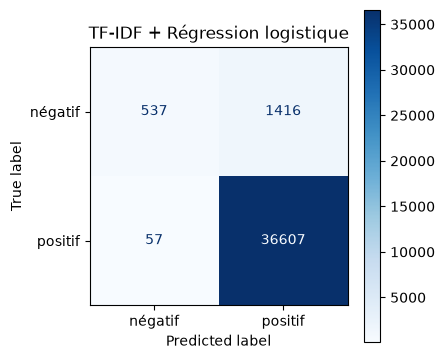

In [10]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["négatif", "positif"]).plot(ax=ax, cmap="Blues")
ax.set_title("TF-IDF + Régression logistique")
plt.tight_layout()
plt.show()

In [11]:
# Mots les plus discriminants du modèle
noms = np.array(vectorizer.get_feature_names_out())
coefs = modele.coef_[0]
top_positif = noms[np.argsort(coefs)[-15:]][::-1]
top_negatif = noms[np.argsort(coefs)[:15]]

print("Mots -> positif :", ", ".join(top_positif))
print()
print("Mots -> négatif :", ", ".join(top_negatif))

Mots -> positif : thanks, great, used, delicious, excellent, wonderful, good, perfect, nice, yummy, loved, enjoyed, this was, fantastic, easy

Mots -> négatif : sorry, not, bland, sounds, rate, try, disappointed, rating, sorry but, just didn, didn like, comment, didn work, wrong, way too


## 7. Comparaison LLM vs NLP

Si le fichier produit par le pipeline LLM existe (`reviews_sentiment.csv`),
on mesure l'accord entre les deux méthodes sur les avis déjà traités.


In [12]:
LLM_PATH = PROJECT_ROOT / "data" / "processed" / "reviews_sentiment.csv"

if LLM_PATH.exists():
    llm = pd.read_csv(LLM_PATH, usecols=["ReviewId", "Sentiment"])
    llm = llm.rename(columns={"Sentiment": "Sentiment_LLM"})

    nlp = resultat[["ReviewId", "Sentiment"]].rename(columns={"Sentiment": "Sentiment_VADER"})
    comparaison = llm.merge(nlp, on="ReviewId", how="inner")
    comparaison = comparaison[comparaison["Sentiment_LLM"].isin([0, 1])
                              & comparaison["Sentiment_VADER"].isin([0, 1])]

    if len(comparaison):
        accord = (comparaison["Sentiment_LLM"] == comparaison["Sentiment_VADER"]).mean()
        print(f"Avis comparés : {len(comparaison):,}".replace(",", " "))
        print(f"Accord LLM / VADER : {accord:.1%}")
        print()
        print(pd.crosstab(comparaison["Sentiment_LLM"],
                          comparaison["Sentiment_VADER"], margins=True))
    else:
        print("Aucun avis commun : lancez d'abord le pipeline LLM.")
else:
    print("Fichier LLM absent : lancez src/data/classify_reviews_llm.py")

Avis comparés : 5 130
Accord LLM / VADER : 91.6%

Sentiment_VADER    0     1   All
Sentiment_LLM                   
0                229   261   490
1                168  4472  4640
All              397  4733  5130


## 8. Conclusion

- **VADER** est immédiat et gratuit, mais il rate les tournures culinaires
  (« too dry », « not bland at all ») et les avis ironiques.
- **TF-IDF + régression logistique** apprend le vocabulaire du corpus et obtient
  une meilleure accuracy, au prix d'un entraînement.
- Le **LLM** reste le plus nuancé, mais coûte ~11-15 $ pour 1,4 M d'avis.
- La colonne `Sentiment` a le même format dans les deux pipelines : les deux
  fichiers se joignent sur `ReviewId`.

### Pour aller plus loin

- `SGDClassifier` ou `LinearSVC` pour entraîner plus vite sur 1,4 M d'avis.
- `ComplementNB` avec `CountVectorizer` : très rapide en NLP.
- Enrichir le lexique VADER avec des termes culinaires
  (`bland`, `dry`, `soggy`, `delicious`...).
